In [5]:
# Преоразовать существующий код для распознавания последовательности рукописных символов в текст.
# Написать генератор произвольной последовательности рукописных символов.

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ
# Сгенерировать набор текстовых строк из допустимых символов.
# Каждому набору поставить в соотвествие массив изоражений соответствующих символов.
# Добавить пробелы для разделения слов, символы пробелов не использовать во время классификации.

# КЛАССИФИКАЦИЯ (k ближайших соседей) (пример AIM practice 2)
# Часть символов оставить для обучения классификатора . Остальные  классифицировать
# по аналогии с примером mnist с прошлого занятия. Т.е. преобразовывать изображение в вектор.
# Выбрать оптимальный классификатор в зависимости от k- количество соседей.
# Метрика для измерения точности классификации, и выбора оптимального классификатора относительно параметра k - accuracy.

# РАСПОЗНАВАНИЕ
# заменить inf_net на последовательное применение следующих шагов:
# 1. генерация изображения с последовательностью символов
# 2. Выделение объектов оставляете как есть.
# 3. Примернить k-nn для решения задачи классификации. 
# 4. Вывести результат

In [1]:
import cv2
import numpy as np
import os
import random
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [7]:
DATA_DIR = "./data" 
CHARACTERS = [x[0].split('\\')[-1] for x in os.walk(path_to_folder)]
IMG_SIZE = 45

def generate_string(num_words=2, word_len_range=(3, 6)):
    words = []
    for _ in range(num_words):
        length = random.randint(*word_len_range)
        valid_chars = [ch for ch in CHARACTERS if ch != " "]
        words.append(''.join(random.choice(valid_chars) for _ in range(length)))
    return ' '.join(words)

def images_from_string(string):
    images = []
    for ch in string:
        if ch == ' ':
            images.append(None) 
            continue
            
        folder_name = 'times' if ch == '*' else ch
        if ch.lower() == 'x': 
            folder_name = 'X'
            
        folder_path = os.path.join(DATA_DIR, folder_name)
        if not os.path.exists(folder_path):
            print(f"Предупреждение: папка {folder_path} не найдена!")
            continue
            
        files = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]
        if not files:
            continue
            
        random_file = random.choice(files)
        img = cv2.imread(os.path.join(folder_path, random_file), cv2.IMREAD_GRAYSCALE)
        images.append(img)
    return images

def combine_images(images, char_spacing=15, word_spacing=45):
    valid_imgs = [img for img in images if img is not None]
    if not valid_imgs:
        return np.ones((IMG_SIZE, IMG_SIZE), dtype=np.uint8) * 255
        
    max_height = max(img.shape[0] for img in valid_imgs)
    
  
    total_width = 0
    for img in images:
        if img is None:
            total_width += word_spacing
        else:
            total_width += img.shape[1] + char_spacing
    total_width -= char_spacing 
    
    canvas = np.ones((max_height, total_width), dtype=np.uint8) * 255
    x_offset = 0
    
    for img in images:
        if img is None:
            x_offset += word_spacing
        else:
            y_offset = (max_height - img.shape[0]) // 2
            canvas[y_offset:y_offset+img.shape[0], x_offset:x_offset+img.shape[1]] = img
            x_offset += img.shape[1] + char_spacing
            
    return canvas

def normalize_symbol(symbol, size=IMG_SIZE):
    h, w = symbol.shape
    img_resized = np.ones((size, size), dtype=np.uint8) * 255
    y_offset = (size - h) // 2
    x_offset = (size - w) // 2
    
    y_end = min(y_offset + h, size)
    x_end = min(x_offset + w, size)
    h_crop = y_end - y_offset
    w_crop = x_end - x_offset
    
    img_resized[y_offset:y_end, x_offset:x_end] = symbol[:h_crop, :w_crop]
    
    return img_resized

def extract_symbols(image, size=IMG_SIZE, min_area=50):
    gray = image if len(image.shape) == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    
    _, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
    
   
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
   
    contours = sorted(contours, key=lambda c: cv2.boundingRect(c)[0])
    bboxes = []
    symbols = []
    
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > min_area:
            symbol = gray[y:y+h, x:x+w]
            symbols.append(normalize_symbol(symbol, size))
            bboxes.append((x, y, w, h))
            
    return symbols, bboxes

def load_data():
    X, y = [], []
    valid_chars = [ch for ch in CHARACTERS if ch != " "] # Не обучаемся на пробелах
    
    for symbol in valid_chars:
        folder_name = 'times' if symbol == '*' else symbol
        folder_path = os.path.join(DATA_DIR, folder_name)
        if not os.path.exists(folder_path): 
            continue
            
        files = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]
        for f in files:
            img = cv2.imread(os.path.join(folder_path, f), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                X.append(normalize_symbol(img).flatten())
                y.append(symbol)
                
    return np.array(X), np.array(y)

NameError: name 'path_to_folder' is not defined

In [3]:
X_all, y_all = load_data()


X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, shuffle=True, random_state=42)

models = {}
accuracies = {}
for k in [1, 3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    models[k] = model
    accuracies[k] = acc
    print(f"KNN (k={k}): точность на тесте = {acc:.1%}")

best_k = max(accuracies, key=accuracies.get)
best_model = models[best_k]
print(f"\nЛучший классификатор: k={best_k} (точность: {accuracies[best_k]:.1%})\n")

KNN (k=1): точность на тесте = 98.8%
KNN (k=3): точность на тесте = 91.9%
KNN (k=5): точность на тесте = 78.5%
KNN (k=7): точность на тесте = 73.6%

Лучший классификатор: k=1 (точность: 98.8%)



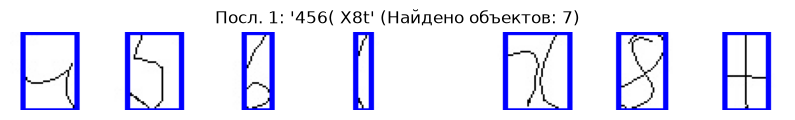

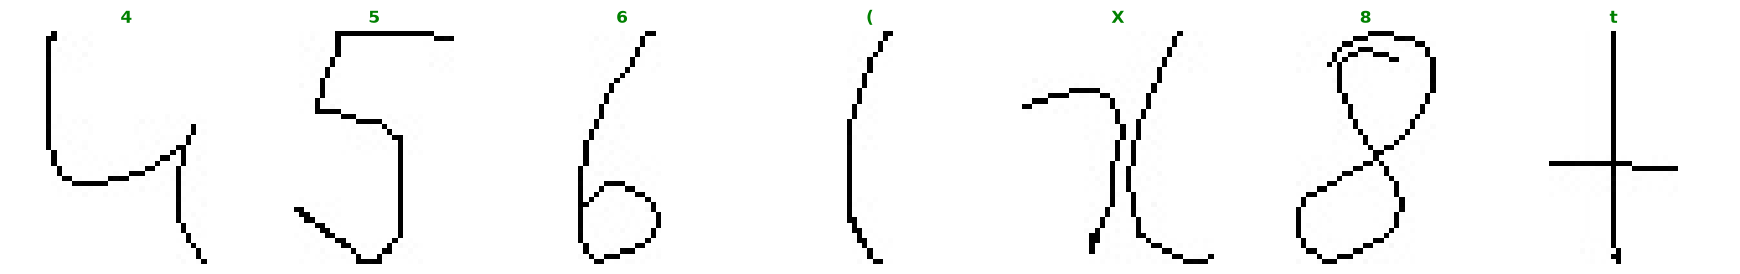

Последовательность 1:
  Оригинал: 456(X8t
  Распознано:              456(X8t
  Точность: 100.0% (7 из 7)



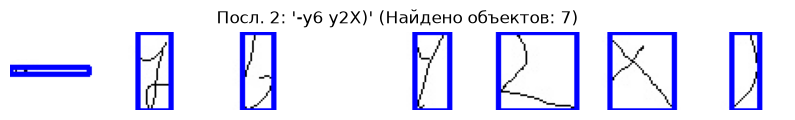

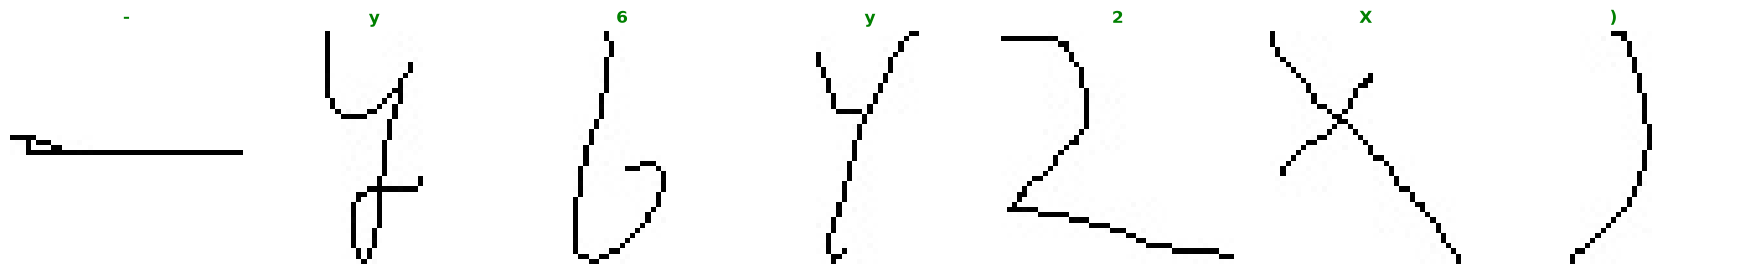

Последовательность 2:
  Оригинал: -y6y2X)
  Распознано:              -y6y2X)
  Точность: 100.0% (7 из 7)



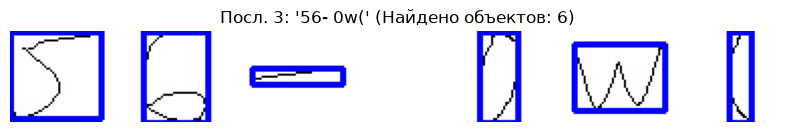

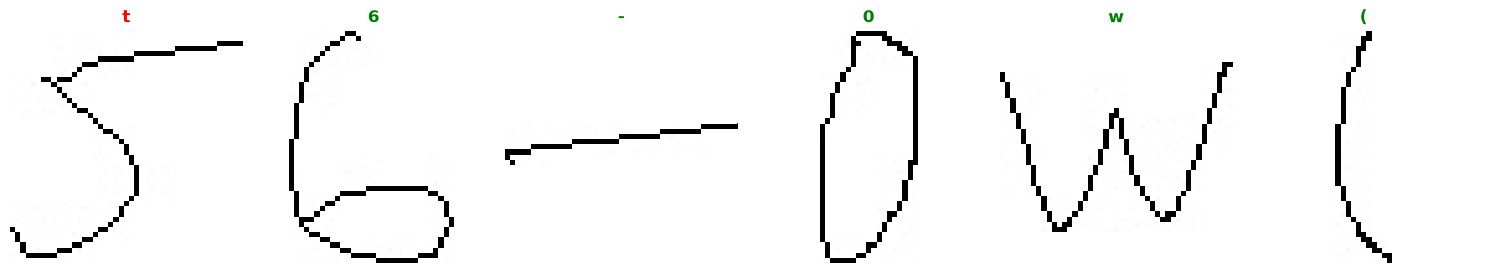

Последовательность 3:
  Оригинал: 56-0w(
  Распознано:              t6-0w(
  Точность: 83.3% (5 из 6)

Средняя точность распознавания по 3 последовательностям: 94.4%


In [6]:
all_accuracies = []
num_sequences = 3

for seq_num in range(num_sequences):
    random_str = generate_string(num_words=2, word_len_range=(3, 5))
    
    image_list = images_from_string(random_str)
    seq_img = combine_images(image_list, char_spacing=15, word_spacing=40)
    
    symbols, bboxes = extract_symbols(seq_img)
    
    recognized_chars = []
    original_predictions = []
    for s in symbols:
        pred = best_model.predict([s.flatten()])[0]
        recognized_chars.append(pred)
        original_predictions.append(pred)
        
    recognized_str = ''.join(recognized_chars)
    
    original_chars_no_space = [ch for ch in random_str if ch != ' ']
    
    if len(recognized_chars) != len(original_chars_no_space):
        print(f"Последовательность {seq_num+1}: Ошибка! Ожидалось {len(original_chars_no_space)}, найдено {len(recognized_chars)} символов.")

    min_len = min(len(original_chars_no_space), len(recognized_chars))
    correct = sum(1 for i in range(min_len) if original_chars_no_space[i] == recognized_chars[i])
    
    if len(recognized_chars) < len(original_chars_no_space):
        recognized_chars.extend(['?'] * (len(original_chars_no_space) - len(recognized_chars)))
    elif len(recognized_chars) > len(original_chars_no_space):
        recognized_chars = recognized_chars[:len(original_chars_no_space)]
        
    accuracy = accuracy_score(original_chars_no_space, recognized_chars)
    all_accuracies.append(accuracy)

    gray_vis = seq_img if len(seq_img.shape) == 2 else cv2.cvtColor(seq_img, cv2.COLOR_RGB2GRAY)
    _, thresh_vis = cv2.threshold(gray_vis, 127, 255, cv2.THRESH_BINARY_INV)
    kernel_vis = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    closed_vis = cv2.morphologyEx(thresh_vis, cv2.MORPH_CLOSE, kernel_vis)
    contours_vis, h = cv2.findContours(closed_vis, cv2.RETR_EXTERNAL, 2) 
    img_rgb = cv2.cvtColor(seq_img, cv2.COLOR_GRAY2RGB)
    
    crops = []
    for i in range(len(contours_vis)):
        cnt = contours_vis[i]
        area = cv2.contourArea(cnt)
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 50:
            cv2.rectangle(img_rgb, (x, y), (x+w, y+h), (0, 0, 255), 2)
            crops.append([x, y, w, h])
    
    plt.figure(figsize=(10, 3))
    plt.subplot(1, 1, 1)
    plt.imshow(img_rgb)
    plt.title(f"Посл. {seq_num+1}: '{random_str}' (Найдено объектов: {len(crops)})")
    plt.axis("off")
    plt.show()
    
    if len(symbols) > 0:
        plt.figure(figsize=(2.5 * len(symbols), 3))
        for idx, s in enumerate(symbols):
            pred = original_predictions[idx]
            
            is_correct = (idx < len(original_chars_no_space)) and (pred == original_chars_no_space[idx])
            title_color = 'green' if is_correct else 'red'
            
            plt.subplot(1, len(symbols), idx + 1)
            plt.imshow(s, cmap="gray")
            plt.title(f"{pred}", color=title_color, fontweight='bold')
            plt.axis("off")
        plt.tight_layout()
        plt.show()
    
    print(f"Последовательность {seq_num+1}:")
    print(f"  Оригинал: {''.join(original_chars_no_space)}")
    print(f"  Распознано:              {recognized_str}")
    print(f"  Точность: {accuracy:.1%} ({correct} из {len(original_chars_no_space)})\n")

print(f"Средняя точность распознавания по {num_sequences} последовательностям: {np.mean(all_accuracies):.1%}")